# How nested evaluation controls selection bias

The inner validation score for a candidate setting is the average of its held-out fold scores:

$$
\overline s_m(\theta)=\frac{1}{K_{\mathrm{in}}}\sum_{j=1}^{K_{\mathrm{in}}} s_{m,j}(\theta).
$$

Here, $m$ identifies an outer split, $\theta$ is a candidate setting, $K_{\mathrm{in}}$ is the number of inner folds, $s_{m,j}(\theta)$ is the held-out score on inner fold $j$, and $\overline s_m(\theta)$ is the mean inner score.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from itertools import product
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.backtest.validation import PurgedKFold
from RiskLabAI.optimization.hyper_parameter_tuning import SampleWeightedPipeline, clf_hyper_fit

FIGURES = ROOT / "outputs" / "figures" / "18_hyperparameter_selection"
TABLES = ROOT / "outputs" / "tables" / "18_hyperparameter_selection"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

minute_data = raw.set_index("time")
bars = pd.DataFrame({
    "Close": minute_data["close"].resample("15min").last(),
    "Volume": minute_data["volume"].resample("15min").sum(),
    "Quote volume": minute_data["quote_volume"].resample("15min").sum(),
    "Trades": minute_data["trades"].resample("15min").sum(),
}).dropna()
log_close = np.log(bars["Close"])
one_bar_return = log_close.diff()
expected_15 = bars["Close"].ewm(span=15, adjust=False).mean()
expected_55 = bars["Close"].ewm(span=55, adjust=False).mean()
feature_frame = pd.DataFrame({
    "Previous return": one_bar_return.shift(1),
    "Distance from EWM 15": (np.log(bars["Close"]) - np.log(expected_15)).shift(1),
    "Distance from EWM 55": (np.log(bars["Close"]) - np.log(expected_55)).shift(1),
    "One-hour return": log_close.diff(4).shift(1),
    "Past volatility": one_bar_return.shift(1).rolling(16).std(),
    "Log volume change": np.log1p(bars["Volume"]).diff().shift(1),
})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename("Forward return")
direction = forward_return.gt(0).where(forward_return.notna()).astype("Int64").rename("Direction")
end_time = bars.index.to_series().shift(-label_horizon).rename("End time")
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame["Direction"].astype(int)
public_forward_return = public_frame["Forward return"].astype(float)
event_times = public_frame["End time"]
absolute_return_weight = public_forward_return.abs()
sample_weight = (absolute_return_weight / absolute_return_weight.median()).clip(lower=0.25, upper=4.0)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def configuration_name(kernel, penalty):
    return f"{kernel.upper()}, C={penalty:g}"

def make_model(kernel, penalty):
    return Pipeline([
        ("scale", StandardScaler()),
        ("svc", SVC(kernel=kernel, C=float(penalty), gamma="scale")),
    ])

def fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights=None):
    model = make_model(kernel, penalty)
    fit_arguments = {}
    if weights is not None:
        fit_arguments["svc__sample_weight"] = weights.iloc[train_indices].to_numpy()
    model.fit(data.iloc[train_indices], labels.iloc[train_indices], **fit_arguments)
    predictions = model.predict(data.iloc[test_indices])
    return {
        "F1": f1_score(labels.iloc[test_indices], predictions, zero_division=0),
        "Precision": precision_score(labels.iloc[test_indices], predictions, zero_division=0),
        "Recall": recall_score(labels.iloc[test_indices], predictions, zero_division=0),
    }

def purged_configuration_scores(data, labels, times, configurations, n_splits=5, embargo=0.01, weights=None):
    splitter = PurgedKFold(n_splits=n_splits, times=times, embargo=embargo)
    splits = list(splitter.split(data, labels))
    records = []
    for order, (kernel, penalty) in enumerate(configurations):
        fold_scores = []
        train_sizes = []
        removals = []
        for train_indices, test_indices in splits:
            values = fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights)
            fold_scores.append(values["F1"])
            train_sizes.append(len(train_indices))
            removals.append(len(data) - len(test_indices) - len(train_indices))
        records.append({
            "Order": order,
            "Configuration": configuration_name(kernel, penalty),
            "Kernel": kernel,
            "C": float(penalty),
            "Mean F1": float(np.mean(fold_scores)),
            "F1 spread": float(np.std(fold_scores, ddof=1)),
            "Smallest fold F1": float(np.min(fold_scores)),
            "Largest fold F1": float(np.max(fold_scores)),
            "Mean training observations": float(np.mean(train_sizes)),
            "Mean removed observations": float(np.mean(removals)),
        })
    return pd.DataFrame(records)

def ordinary_configuration_scores(data, labels, times, configurations, n_splits=5, weights=None):
    splits = list(KFold(n_splits=n_splits, shuffle=False).split(data))
    records = []
    for order, (kernel, penalty) in enumerate(configurations):
        fold_scores = []
        for train_indices, test_indices in splits:
            fold_scores.append(fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights)["F1"])
        records.append({
            "Order": order,
            "Configuration": configuration_name(kernel, penalty),
            "Kernel": kernel,
            "C": float(penalty),
            "Mean F1": float(np.mean(fold_scores)),
            "F1 spread": float(np.std(fold_scores, ddof=1)),
            "Smallest fold F1": float(np.min(fold_scores)),
            "Largest fold F1": float(np.max(fold_scores)),
        })
    return pd.DataFrame(records)

def selected_row(frame):
    ordered = frame.sort_values(["Mean F1", "Order"], ascending=[False, True])
    return ordered.iloc[0]

def residual_overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=True)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum(int(int(index) not in allowed_positions) for index in train_indices)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Data

,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Market,Bitcoin to Tether spot market
3,Bar length,15 minutes
4,Label horizon,2 hours
5,Analysis start,2021-01-01 04:15:00
6,Analysis end,2021-01-31 21:45:00
7,Observations,"2,951"
8,Archive SHA256,9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A2...


,Label,Observations,Share
0,Non-positive two-hour return,1441,0.488309
1,Positive two-hour return,1510,0.511691


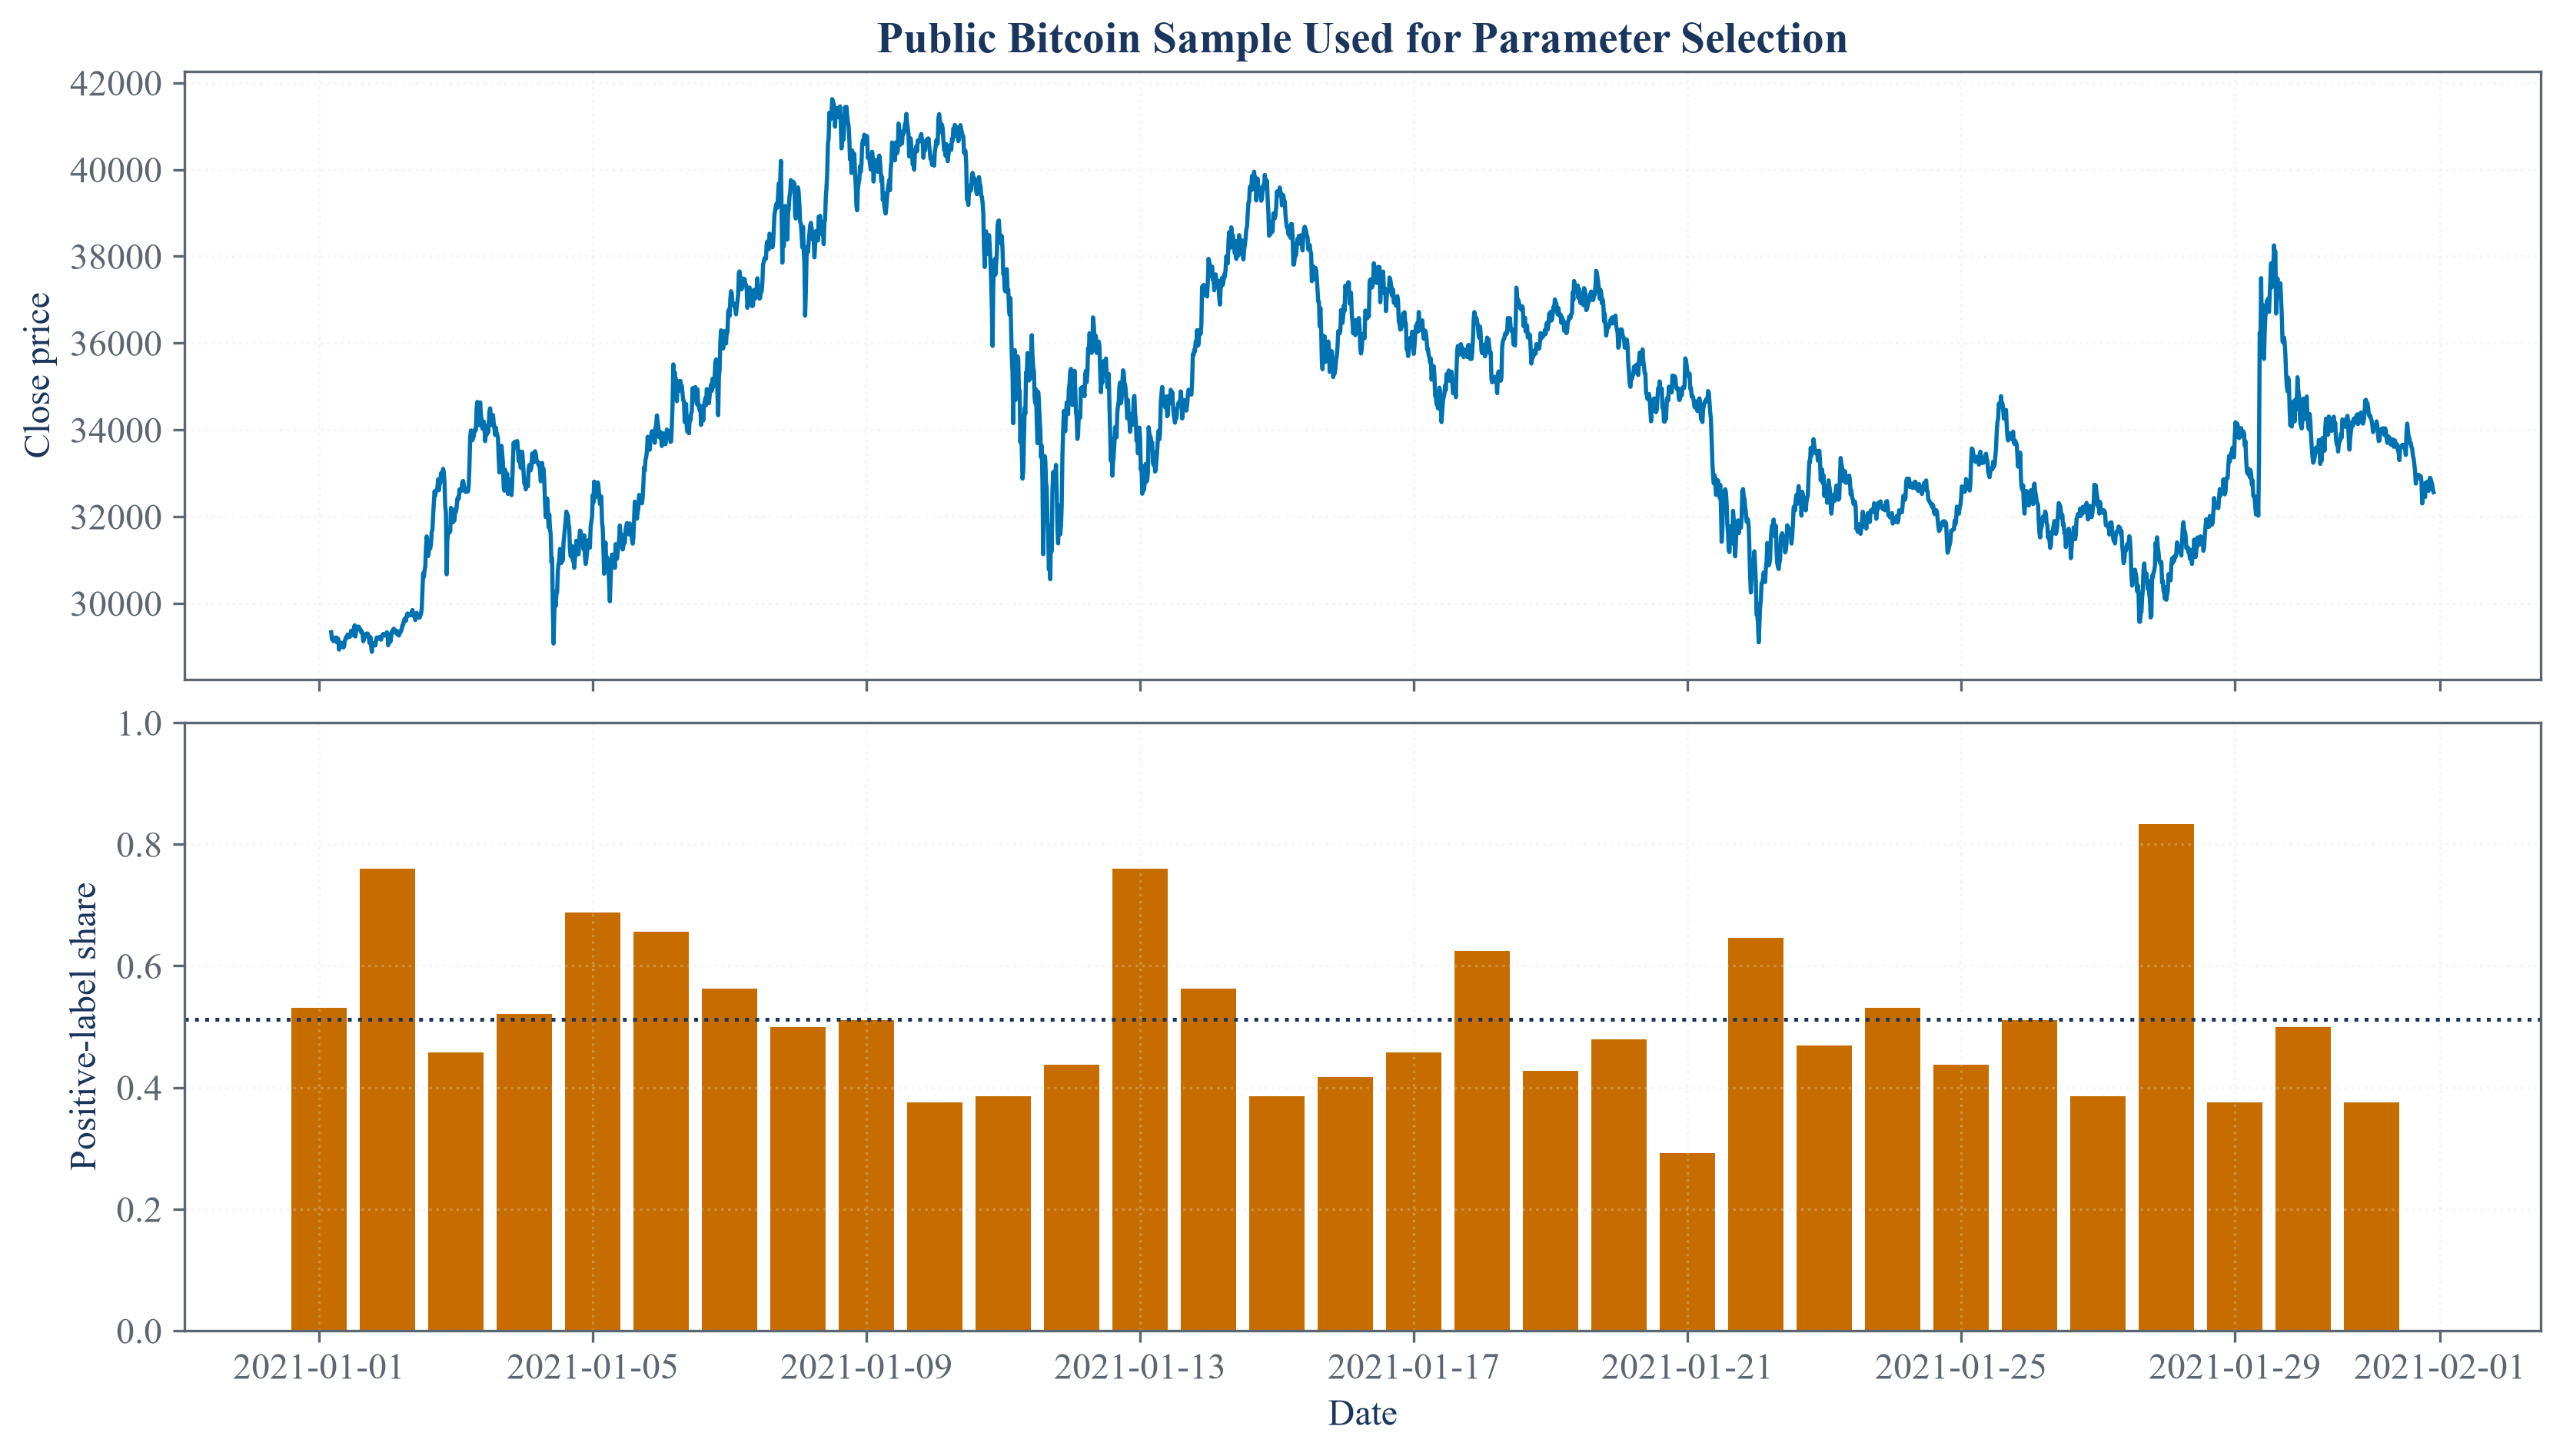

In [2]:
data_provenance = pd.DataFrame({
    "Field": ["Archive", "Provider", "Market", "Bar length", "Label horizon", "Analysis start", "Analysis end", "Observations", "Archive SHA256"],
    "Value": ["BTCUSDT-1m-2021-01.zip", "Binance Data Vision", "Bitcoin to Tether spot market", "15 minutes", "2 hours", str(public_x.index.min()), str(public_x.index.max()), f"{len(public_x):,}", data_hash],
})
label_balance = pd.DataFrame({
    "Label": ["Non-positive two-hour return", "Positive two-hour return"],
    "Observations": [(public_y == 0).sum(), (public_y == 1).sum()],
    "Share": [(public_y == 0).mean(), (public_y == 1).mean()],
})
save_table(data_provenance, "data_provenance", "Fixed public observations used in Chapter 16.", "tab:chapter16-data-provenance")
save_table(label_balance, "label_balance", "Two-hour direction labels in the public sample.", "tab:chapter16-label-balance", fit=False)
display(data_provenance)
display(label_balance)

daily_direction = public_y.resample("1D").mean()
figure, axes = plt.subplots(2, 1, figsize=(11.0, 6.2), sharex=True, constrained_layout=True)
axes[0].plot(bars.loc[public_x.index.min():public_x.index.max(), "Close"], color=palette["cyan"], linewidth=1.3)
axes[0].set_title("Public Bitcoin Sample Used for Parameter Selection")
axes[0].set_ylabel("Close price")
axes[0].grid(alpha=0.30)
axes[1].bar(daily_direction.index, daily_direction.to_numpy(), width=0.8, color=palette["amber"])
axes[1].axhline(public_y.mean(), color=palette["text"], linestyle=":", linewidth=1.2)
axes[1].set_ylabel("Positive-label share")
axes[1].set_xlabel("Date")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.30)
figure.savefig(FIGURES / "public_selection_sample.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_selection_sample.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_selection_sample.png")))
plt.close(figure)

## Choosing Inside Each Outer Split

Each outer training set chooses the setting with the largest inner score:

$$
\widehat\theta_m=\arg\max_{\theta\in\Theta}\overline s_m(\theta).
$$

Here, $\Theta$ is the finite set of candidate settings, $\widehat\theta_m$ is the setting selected inside outer split $m$, and $\overline s_m(\theta)$ is the inner score defined above. The outer test observations do not enter this choice.

In [3]:
configuration_grid = [(kernel, penalty) for kernel, penalty in product(["linear", "rbf"], [0.01, 0.1, 1.0, 10.0])]
configuration_catalog = pd.DataFrame({
    "Configuration": np.arange(1, len(configuration_grid) + 1),
    "Kernel": [kernel for kernel, penalty in configuration_grid],
    "C": [penalty for kernel, penalty in configuration_grid],
    "Name": [configuration_name(kernel, penalty) for kernel, penalty in configuration_grid],
})
save_table(configuration_catalog, "configuration_catalog", "Candidate settings in the nested public-data search.", "tab:chapter16-configuration-catalog", fit=False)
display(configuration_catalog)

outer_splitter = PurgedKFold(n_splits=5, times=event_times, embargo=0.01)
outer_splits = list(outer_splitter.split(public_x, public_y))
nested_records = []
inner_surface_records = []
for outer_fold, (outer_train, outer_test) in enumerate(outer_splits, start=1):
    inner_x = public_x.iloc[outer_train]
    inner_y = public_y.iloc[outer_train]
    inner_times = event_times.iloc[outer_train]
    inner_weights = sample_weight.iloc[outer_train]
    inner_surface = purged_configuration_scores(inner_x, inner_y, inner_times, configuration_grid, n_splits=4, embargo=0.01, weights=inner_weights)
    chosen = selected_row(inner_surface)
    outer_values = fit_and_score(chosen["Kernel"], chosen["C"], public_x, public_y, outer_train, outer_test, sample_weight)
    nested_records.append({
        "Outer fold": outer_fold,
        "Outer test begins": str(public_x.index[outer_test[0]]),
        "Outer test ends": str(public_x.index[outer_test[-1]]),
        "Training observations": len(outer_train),
        "Test observations": len(outer_test),
        "Selected kernel": chosen["Kernel"],
        "Selected C": chosen["C"],
        "Inner F1": chosen["Mean F1"],
        "Outer F1": outer_values["F1"],
        "Selection gap": chosen["Mean F1"] - outer_values["F1"],
    })
    current_surface = inner_surface[["Configuration", "Kernel", "C", "Mean F1", "F1 spread"]].copy()
    current_surface.insert(0, "Outer fold", outer_fold)
    inner_surface_records.append(current_surface)
nested_fold_results = pd.DataFrame(nested_records)
nested_inner_surface = pd.concat(inner_surface_records, ignore_index=True)
save_table(nested_fold_results, "nested_fold_results", "Inner choices and untouched outer scores across five protected outer folds.", "tab:chapter16-nested-fold-results")
save_table(nested_inner_surface, "nested_inner_surface", "Complete inner score surface across the five outer folds.", "tab:chapter16-nested-inner-surface")
display(nested_fold_results)
display(nested_inner_surface)

,Configuration,Kernel,C,Name
0,1,linear,0.01,"LINEAR, C=0.01"
1,2,linear,0.10,"LINEAR, C=0.1"
2,3,linear,1,"LINEAR, C=1"
3,4,linear,10,"LINEAR, C=10"
4,5,rbf,0.01,"RBF, C=0.01"
5,6,rbf,0.10,"RBF, C=0.1"
6,7,rbf,1,"RBF, C=1"
7,8,rbf,10,"RBF, C=10"


,Outer fold,Outer test begins,Outer test ends,Training observations,Test observations,Selected kernel,Selected C,Inner F1,Outer F1,Selection gap
0,1,2021-01-01 04:15:00,2021-01-07 07:45:00,2323,591,rbf,10,0.373317,0.524752,-0.151435
1,2,2021-01-07 08:00:00,2021-01-13 11:15:00,2316,590,linear,0.10,0.549229,0.536585,0.012644
2,3,2021-01-13 11:30:00,2021-01-19 14:45:00,2316,590,linear,0.01,0.496925,0.135593,0.361331
3,4,2021-01-19 15:00:00,2021-01-25 18:15:00,2316,590,rbf,1,0.549122,0.552352,-0.003230
4,5,2021-01-25 18:30:00,2021-01-31 21:45:00,2353,590,rbf,10,0.527435,0.525773,0.001661


,Outer fold,Configuration,Kernel,C,Mean F1,F1 spread
0,1,"LINEAR, C=0.01",linear,0.01,0.128129,0.174257
1,1,"LINEAR, C=0.1",linear,0.10,0.152524,0.177316
2,1,"LINEAR, C=1",linear,1,0.151872,0.173546
3,1,"LINEAR, C=10",linear,10,0.151872,0.173546
4,1,"RBF, C=0.01",rbf,0.01,0,0
5,1,"RBF, C=0.1",rbf,0.10,0.153599,0.073707
6,1,"RBF, C=1",rbf,1,0.325146,0.115545
7,1,"RBF, C=10",rbf,10,0.373317,0.041816
8,2,"LINEAR, C=0.01",linear,0.01,0.537596,0.235012
9,2,"LINEAR, C=0.1",linear,0.10,0.549229,0.211782


The nested score and the average selection gap are given by:

$$
\widehat S_{\mathrm{nested}}=\frac{1}{K_{\mathrm{out}}}\sum_{m=1}^{K_{\mathrm{out}}} s_m^{\mathrm{out}}(\widehat\theta_m),
\qquad
\widehat O=\frac{1}{K_{\mathrm{out}}}\sum_{m=1}^{K_{\mathrm{out}}}\left[\overline s_m(\widehat\theta_m)-s_m^{\mathrm{out}}(\widehat\theta_m)\right].
$$

Here, $K_{\mathrm{out}}$ is the number of outer folds, $s_m^{\mathrm{out}}(\widehat\theta_m)$ is the score on untouched outer fold $m$, $\widehat S_{\mathrm{nested}}$ is their mean, and $\widehat O$ is the average difference between the selected inner score and its outer score.

,Quantity,Value
0,Candidate settings,8
1,Outer folds,5
2,Inner folds,4
3,Best full-sample inner F1,0.526116
4,Mean selected inner F1,0.499206
5,Mean untouched outer F1,0.455011
6,Mean selection gap,0.044194
7,Smallest outer F1,0.135593
8,Largest outer F1,0.552352


,Selected kernel,Selected C,Outer-fold selections,Selection share
0,linear,0.01,1,0.2
1,linear,0.10,1,0.2
2,rbf,1,1,0.2
3,rbf,10,2,0.4


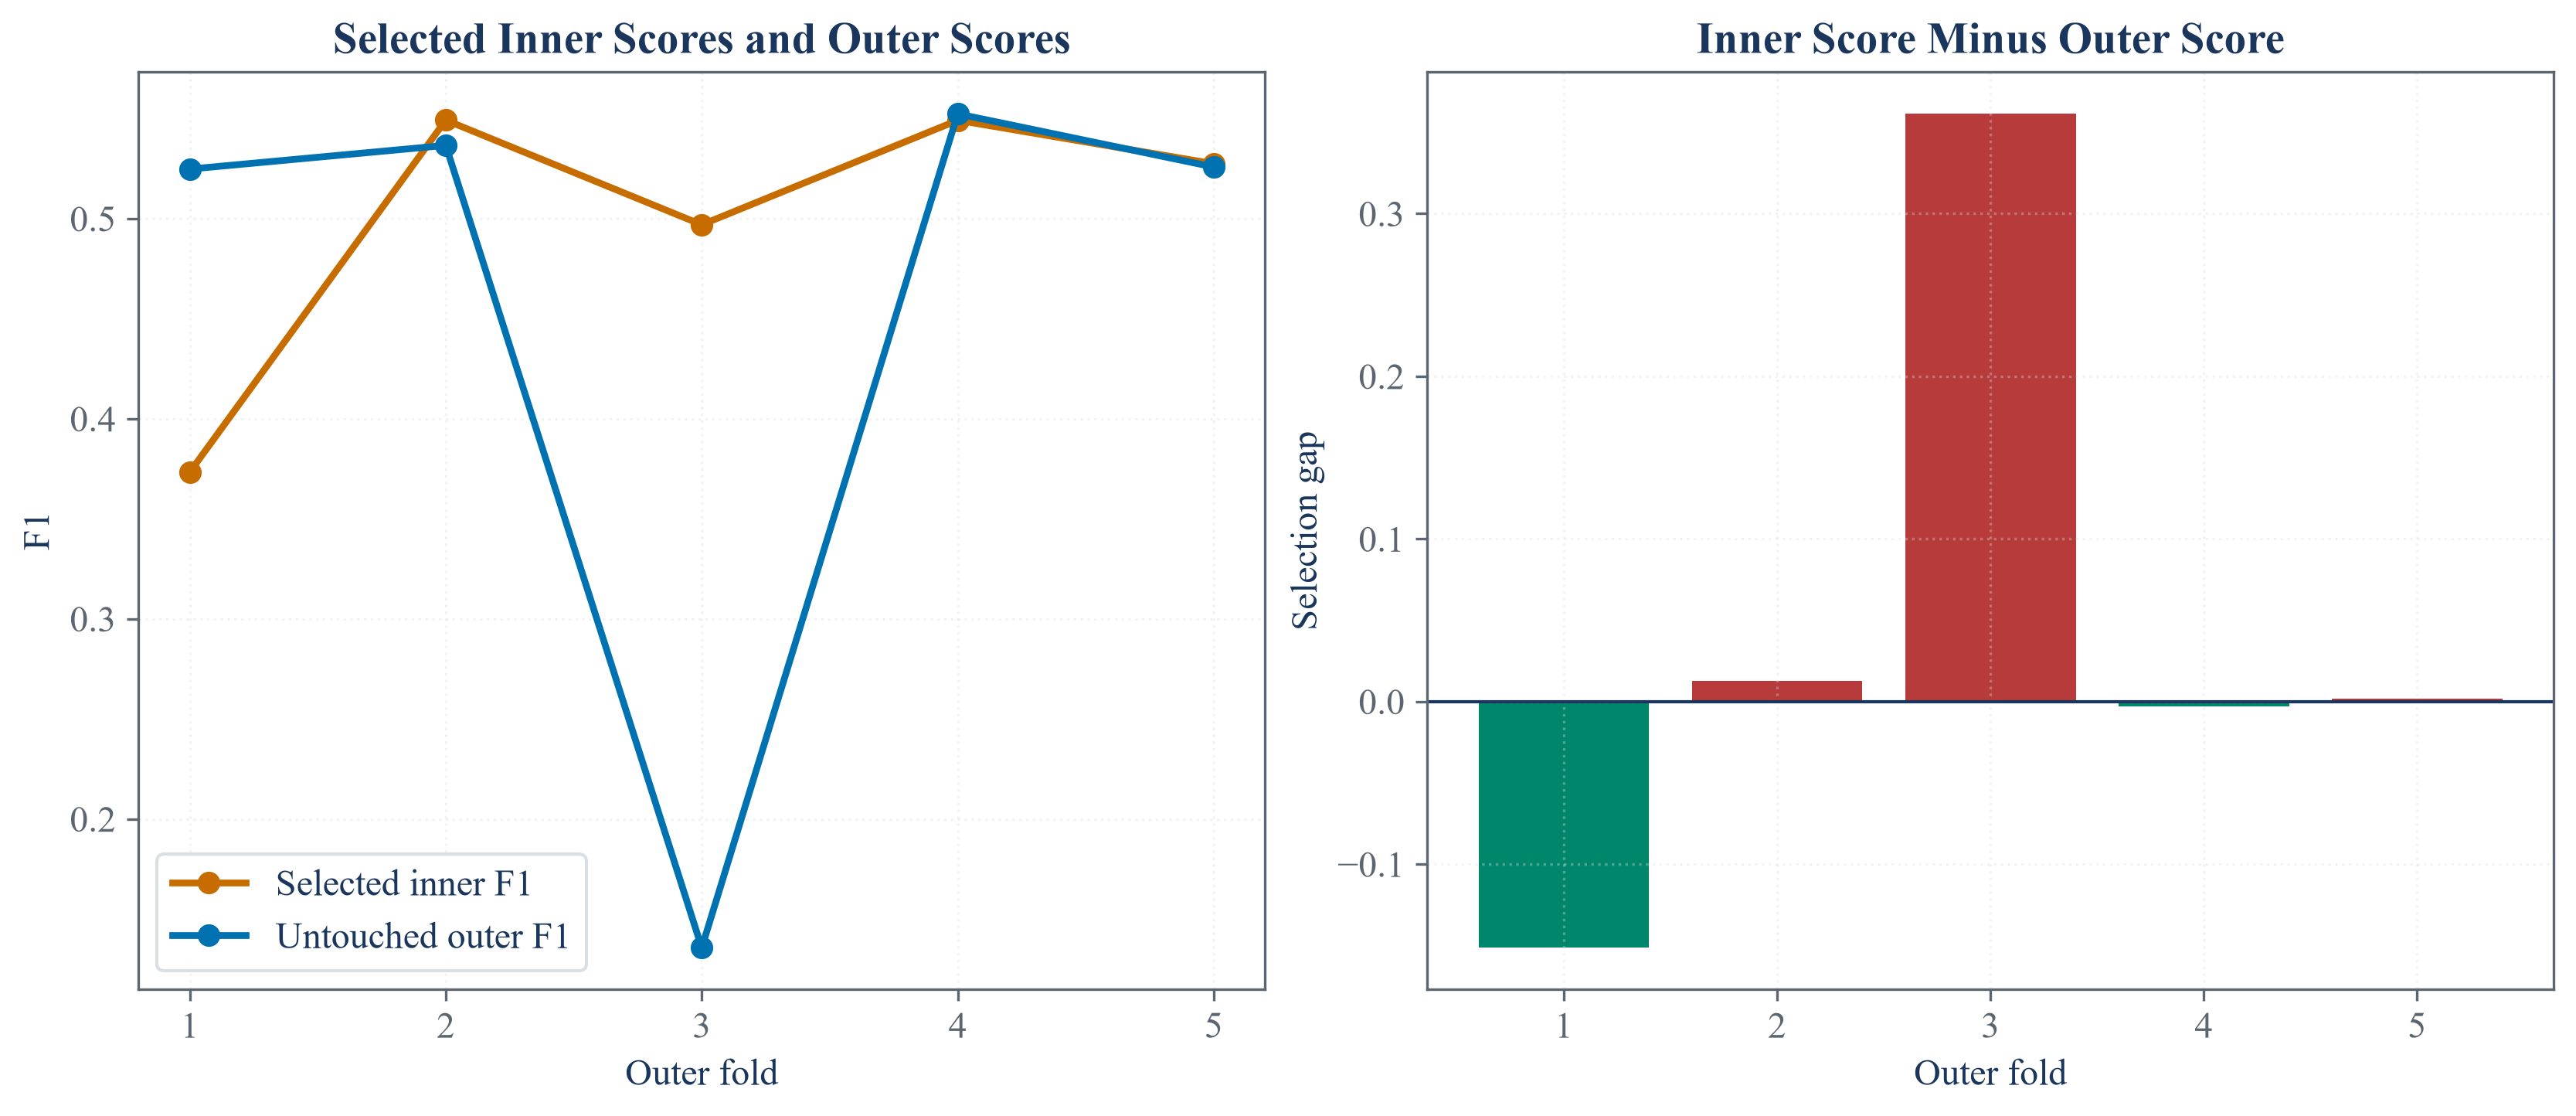

In [4]:
full_surface = purged_configuration_scores(public_x, public_y, event_times, configuration_grid, n_splits=5, embargo=0.01, weights=sample_weight)
apparent_best = selected_row(full_surface)
nested_summary = pd.DataFrame({
    "Quantity": ["Candidate settings", "Outer folds", "Inner folds", "Best full-sample inner F1", "Mean selected inner F1", "Mean untouched outer F1", "Mean selection gap", "Smallest outer F1", "Largest outer F1"],
    "Value": [len(configuration_grid), 5, 4, apparent_best["Mean F1"], nested_fold_results["Inner F1"].mean(), nested_fold_results["Outer F1"].mean(), nested_fold_results["Selection gap"].mean(), nested_fold_results["Outer F1"].min(), nested_fold_results["Outer F1"].max()],
})
selection_frequency = nested_fold_results.groupby(["Selected kernel", "Selected C"], as_index=False).size().rename(columns={"size": "Outer-fold selections"})
selection_frequency["Selection share"] = selection_frequency["Outer-fold selections"] / len(nested_fold_results)
save_table(nested_summary, "nested_summary", "Nested-selection summary for the public experiment.", "tab:chapter16-nested-summary", fit=False)
save_table(selection_frequency, "nested_selection_frequency", "Frequency of selected settings across protected outer folds.", "tab:chapter16-nested-selection-frequency", fit=False)
display(nested_summary)
display(selection_frequency)

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.7), constrained_layout=True)
axes[0].plot(nested_fold_results["Outer fold"], nested_fold_results["Inner F1"], marker="o", linewidth=2.1, color=palette["amber"], label="Selected inner F1")
axes[0].plot(nested_fold_results["Outer fold"], nested_fold_results["Outer F1"], marker="o", linewidth=2.1, color=palette["cyan"], label="Untouched outer F1")
axes[0].set_title("Selected Inner Scores and Outer Scores")
axes[0].set_xlabel("Outer fold")
axes[0].set_ylabel("F1")
axes[0].set_xticks(nested_fold_results["Outer fold"])
axes[0].grid(alpha=0.35)
axes[0].legend()
axes[1].bar(nested_fold_results["Outer fold"], nested_fold_results["Selection gap"], color=np.where(nested_fold_results["Selection gap"] >= 0, palette["rose"], palette["green"]))
axes[1].axhline(0, color=palette["text"], linewidth=1.0)
axes[1].set_title("Inner Score Minus Outer Score")
axes[1].set_xlabel("Outer fold")
axes[1].set_ylabel("Selection gap")
axes[1].set_xticks(nested_fold_results["Outer fold"])
axes[1].grid(alpha=0.35)
figure.savefig(FIGURES / "nested_inner_outer_scores.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "nested_inner_outer_scores.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "nested_inner_outer_scores.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(public_x) == 2951
assert public_x.index.equals(event_times.index)
assert public_y.isin([0, 1]).all()
assert label_balance["Observations"].sum() == len(public_y)
assert np.isclose(label_balance["Share"].sum(), 1)
assert configuration_catalog.shape == (8, 4)
assert len(outer_splits) == 5
assert nested_fold_results.shape == (5, 10)
assert nested_inner_surface.shape == (40, 6)
assert nested_fold_results["Inner F1"].between(0, 1).all()
assert nested_fold_results["Outer F1"].between(0, 1).all()
assert nested_fold_results["Training observations"].gt(0).all()
assert nested_fold_results["Test observations"].sum() == len(public_x)
assert full_surface.shape == (8, 10)
assert nested_summary.shape == (9, 2)
assert selection_frequency["Outer-fold selections"].sum() == 5
assert np.isclose(selection_frequency["Selection share"].sum(), 1)
for train_indices, test_indices in outer_splits:
    assert len(set(train_indices).intersection(test_indices)) == 0
    assert residual_overlap_count(train_indices, test_indices, event_times) == 0
assert (FIGURES / "public_selection_sample.pdf").is_file()
assert (FIGURES / "nested_inner_outer_scores.pdf").is_file()
assert (TABLES / "data_provenance.tex").is_file()
assert (TABLES / "label_balance.tex").is_file()
assert (TABLES / "configuration_catalog.tex").is_file()
assert (TABLES / "nested_fold_results.tex").is_file()
assert (TABLES / "nested_inner_surface.tex").is_file()
assert (TABLES / "nested_summary.tex").is_file()
assert (TABLES / "nested_selection_frequency.tex").is_file()